# Bayshore farmland and flooding: where the model stands (October 2026)

A short progress update for the ag-econ group. We built a computer model of how water moves
over the land in Salem, Cumberland and Gloucester counties. Then we ran it under different
tides, storms, dike conditions and sea levels. Every figure below comes from those model runs.
No insurance data is used here.

## The model in brief

- **What it is.** SFINCS, a fast, widely used flood model from Deltares. It moves tide and rain
  water across a map of ground heights, hour by hour.
- **Where.** The Delaware River and Bay side of the three counties: 38 whole watersheds from Big
  Timber Creek to West Creek, about 3,460 km² (1,340 mi²). Gloucester's Atlantic-side headwaters
  are left out. They hold about 10% of its cropland.
- **How fine.** The model grid is 100 m, but inside each cell it keeps ground height at 10 m
  detail, so the low spots in a field are seen.
- **Inputs:**
  - *Ground height:* NJ 2021 lidar; creek and river bottoms from USACE and NOAA surveys.
  - *Tide:* observed hourly water levels at five NOAA gauges, Philadelphia to Cape May.
  - *Rain:* radar rainfall (NOAA MRMS; Stage IV before 2015).
  - *Soils:* USDA SSURGO, which sets how much rain soaks in.
  - *Dikes ("meadow banks"):* 101 km of bank from the USACE National Levee Database. Crest
    heights are read from the lidar, and each farm dike has a one-way tide gate.
- **Fields.** 13,699 farm fields covering 76,400 ha (189,000 acres). These are the farm
  polygons in NJDEP's 2020 Land Use/Land Cover map: cropland and pasture, orchards and
  nurseries, "agricultural wetland" (wet farmland), and other farm uses. The crop on each field
  comes from the USDA Cropland Data Layer (CDL) 2024.
- **Checks so far.** The modelled tide in the lower Maurice River (Bivalve) is within about
  10 cm of the gauge. Side creeks (Cohansey, Alloway) are within 10–17 cm.

**Scenarios: the same event under different conditions**

| | |
|---|---|
| Events | an ordinary month of tides (October 2024, no storm, no rain); Hurricane Sandy (October 2012) |
| Sea level | today, +0.3 m, +0.6 m, +1.0 m (about +1, +2 and +3.3 ft) |
| Dikes | as built today; removed; a 100 m breach in every farm dike |

"Flooded" means more than 5 cm (2 in) of water. A field counts as flooded when at least 10% of
it is under water. Areas are in hectares (1 ha = 2.47 acres).

In [1]:
# Setup: run from the repo's notebooks/ folder in the project environment (see CLAUDE.md).
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent
sys.path.insert(0, str(ROOT))
from agri_sfincs import config, domain  # noqa: E402  (also sets up PROJ)

import geopandas as gpd  # noqa: E402
import matplotlib.pyplot as plt  # noqa: E402
import pandas as pd  # noqa: E402
import xarray as xr  # noqa: E402
from matplotlib.dates import DateFormatter  # noqa: E402
from matplotlib.patches import Patch  # noqa: E402
from shapely.geometry import LineString  # noqa: E402

%config InlineBackend.figure_format = "png"
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": "#e1e0d9", "grid.linewidth": 0.6,
                     "axes.edgecolor": "#c3c2b7", "axes.titleweight": "bold",
                     "axes.titlesize": 11, "axes.labelcolor": "#52514e",
                     "xtick.color": "#52514e", "ytick.color": "#52514e"})

RUNS = config.MODELS / "v1_100m" / "runs"  # model runs (on scratch)
UTM = domain.EPSG
LEVELS = [0, 30, 60, 100]  # sea-level rise, cm
LEVEL_NAME = {0: "today", 30: "+0.3 m", 60: "+0.6 m", 100: "+1.0 m"}
SLR_COL = {0: "#86b6ef", 30: "#3987e5", 60: "#1c5cab", 100: "#0d366b"}  # light -> dark = more rise
DIKE_NAME = {"intact": "dikes as built", "breach_all_farm": "100 m breach in every farm dike",
             "removed": "dikes removed"}
DIKE_COL = {"intact": "#2a78d6", "breach_all_farm": "#1baf7a", "removed": "#eb6834"}

# Farm fields with per-scenario results (scripts/field_flood_classes.py)
fields = gpd.read_file(config.DATA / "analysis" / "field_flood_classes.gpkg")
outline = gpd.read_file(config.REGION_DIR / "model_outline.geojson").to_crs(UTM)
counties = gpd.read_file(config.REGION_DIR / "counties.gpkg").to_crs(UTM)
states = gpd.read_file(config.REGION_DIR / "states_cb500k.gpkg").to_crs(UTM)
crest = gpd.read_file(config.DATA / "structures" / "dikes_built.gpkg", layer="crest_points")
dikes = gpd.GeoDataFrame(
    geometry=[LineString(g.sort_values("s").geometry.tolist())
              for _, g in crest.groupby("name") if len(g) > 1], crs=crest.crs).to_crs(UTM)
gauges = gpd.GeoDataFrame(
    pd.DataFrame(domain.NOAA_STATIONS),
    geometry=gpd.points_from_xy([s["lon"] for s in domain.NOAA_STATIONS],
                                [s["lat"] for s in domain.NOAA_STATIONS]), crs=4326).to_crs(UTM)
wl = xr.open_dataset(config.GAUGE_DIR / "waterlevel_forcing_navd88.nc")
tide_sjs = wl.waterlevel.sel(stations="8537121").to_series()  # Ship John Shoal, m NAVD88


def daily_cropland_ha(run, baseline_run):
    """Cropland (CDL) under > 5 cm of water each day, ha. The first spin-up day of the
    present-day run is subtracted: ponds that CDL calls crops."""
    def total(r):
        d = pd.read_csv(RUNS / r / "summary" / "daily_county_crop.csv", parse_dates=["date"])
        return d.groupby("date").area_gt_5cm_km2.sum()
    return ((total(run) - total(baseline_run).iloc[0]) * 100).clip(lower=0)


def bare_map(ax, box):
    ax.set_facecolor("#dcebf7")  # water / outside
    states.plot(ax=ax, color="#f4f4f2", edgecolor="#c3c2b7", lw=0.5)
    counties.plot(ax=ax, color="#f4f4f2", edgecolor="#c3c2b7", lw=0.5)
    outline.boundary.plot(ax=ax, color="#52514e", lw=0.8)
    ax.set_xlim(box[0], box[2]); ax.set_ylim(box[1], box[3])
    ax.set_xticks([]); ax.set_yticks([]); ax.grid(False); ax.set_aspect("equal")
    for s in ax.spines.values():
        s.set_visible(True)


## 1. The model area

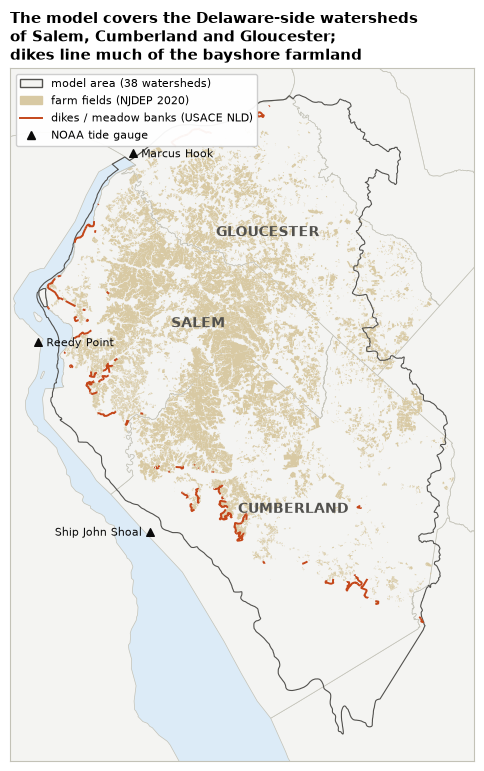

In [2]:
box = outline.total_bounds + [-4000, -4000, 4000, 4000]
fig, ax = plt.subplots(figsize=(6.5, 9))
bare_map(ax, box)
fields.plot(ax=ax, color="#d8c9a3", lw=0)
dikes.plot(ax=ax, color="#c4471a", lw=1.4)
gauges.plot(ax=ax, color="#0b0b0b", markersize=30, marker="^", zorder=5)
for _, g in gauges.iterrows():
    if box[0] < g.geometry.x < box[2] and box[1] < g.geometry.y < box[3]:
        left = g["id"] == "8537121"  # keep the label off the Cumberland dikes
        ax.annotate(g["name"].split(",")[0], (g.geometry.x, g.geometry.y), xytext=(-6 if left else 6, -3),
                    textcoords="offset points", fontsize=8, color="#0b0b0b", ha="right" if left else "left")
for _, c in counties[counties.fips.isin(domain.COUNTIES)].iterrows():
    p = c.geometry.intersection(outline.geometry.iloc[0]).representative_point()
    ax.annotate(c["name"].upper(), (p.x, p.y), ha="center", fontsize=10, color="#52514e",
                weight="bold")
ax.legend(handles=[Patch(fc="#f4f4f2", ec="#52514e", label="model area (38 watersheds)"),
                   Patch(color="#d8c9a3", label="farm fields (NJDEP 2020)"),
                   plt.Line2D([], [], color="#c4471a", lw=1.4, label="dikes / meadow banks (USACE NLD)"),
                   plt.Line2D([], [], color="#0b0b0b", marker="^", lw=0, label="NOAA tide gauge")],
          loc="upper left", fontsize=8, framealpha=0.95)
ax.set_title("The model covers the Delaware-side watersheds\nof Salem, Cumberland and Gloucester;\n"
             "dikes line much of the bayshore farmland", loc="left")
plt.show()

## 2. An ordinary month of tides (October 2024) with sea-level rise

No storm and no rain: only the tides of an average month, with the sea raised. The question is how
much farmland the tide reaches, with and without the dikes.

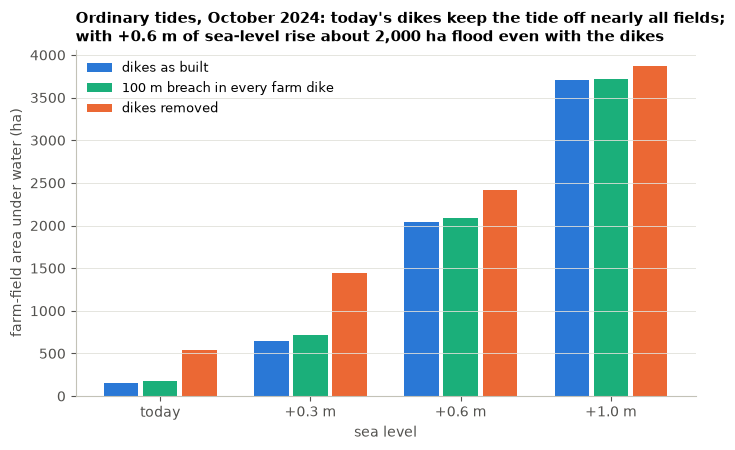

dikes,dikes as built,100 m breach in every farm dike,dikes removed
sea level,,,
today,156,180,540
+0.3 m,643,721,"1,439"
+0.6 m,"2,036","2,084","2,418"
+1.0 m,"3,701","3,714","3,870"


In [3]:
rows = []
for dk in DIKE_NAME:
    for lv in LEVELS:
        s = fields[f"share_{dk}_slr{lv:03d}"]
        hit = s >= 0.10
        rows.append({"dikes": dk, "sea level": LEVEL_NAME[lv], "fields flooded": int(hit.sum()),
                     "ha under water": (s * fields.ha)[hit].sum()})
tab = pd.DataFrame(rows)

fig, ax = plt.subplots(figsize=(8, 4.5))
w = 0.26
for i, dk in enumerate(DIKE_NAME):
    t = tab[tab.dikes == dk]
    ax.bar([j + (i - 1) * w for j in range(4)], t["ha under water"], width=w - 0.03,
           color=DIKE_COL[dk], label=DIKE_NAME[dk])
ax.set_xticks(range(4), [LEVEL_NAME[l] for l in LEVELS])
ax.set_xlabel("sea level")
ax.set_ylabel("farm-field area under water (ha)")
ax.grid(axis="x", visible=False)
ax.legend(frameon=False, fontsize=9)
ax.set_title("Ordinary tides, October 2024: today's dikes keep the tide off nearly all fields;\n"
             "with +0.6 m of sea-level rise about 2,000 ha flood even with the dikes", loc="left")
plt.show()

pd.options.display.float_format = "{:,.0f}".format
tab.assign(dikes=tab.dikes.map(DIKE_NAME)).pivot(index="sea level", columns="dikes",
                                                 values="ha under water").loc[list(LEVEL_NAME.values()), list(DIKE_NAME.values())]

- The dikes matter most at +0.3 m. Beyond that they are overtopped, and removing them changes
  less and less.
- A 100 m breach in every farm dike barely changes one month. A gap that size fills a diked field
  slowly, over many tides.
- Even today about 150 ha is under water at high tide, mostly in "agricultural wetland" fields:
  wet farmland that the tide already reaches.

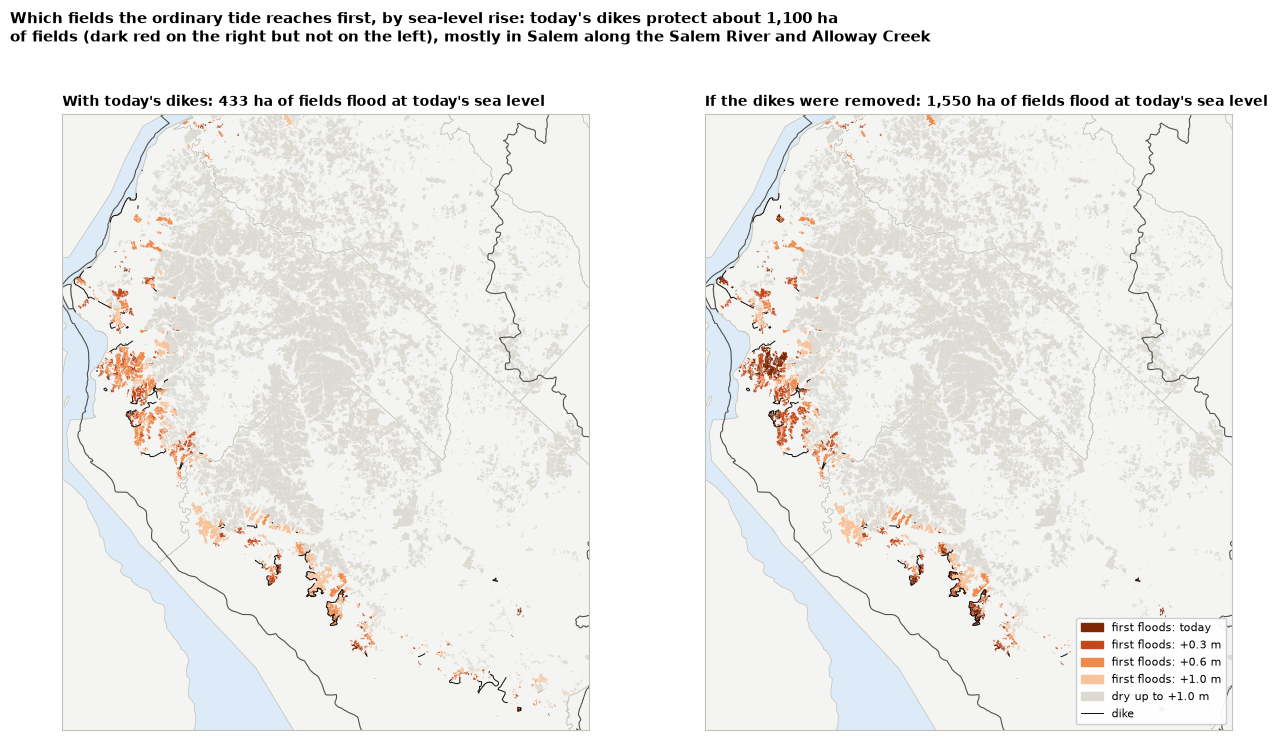

In [4]:
def first_level(dk):
    col = fields[f"first_{dk}"].map({0.0: 0, 0.3: 30, 0.6: 60, 1.0: 100})
    return col

FIRST_COL = {0: "#7f2704", 30: "#c4471a", 60: "#f08a4b", 100: "#f8c39a"}  # dark = floods sooner
flooding = fields[fields.first_removed.notna() | fields.first_intact.notna()]
x0, y0, x1, y1 = flooding[flooding.county != "Gloucester"].total_bounds
zoom = [x0 - 1500, y0 - 1500, x1 + 1500, y1 + 1500]

fig, axes = plt.subplots(1, 2, figsize=(13, 7.5))
for ax, dk, ttl in zip(axes, ["intact", "removed"], ["With today's dikes", "If the dikes were removed"]):
    bare_map(ax, zoom)
    lev = first_level(dk)
    fields[lev.isna()].plot(ax=ax, color="#dcdad3", lw=0)
    for lv in LEVELS:
        fields[lev == lv].plot(ax=ax, color=FIRST_COL[lv], lw=0)
    dikes.plot(ax=ax, color="#0b0b0b", lw=0.7)
    ha = {lv: fields.ha[lev == lv].sum() for lv in LEVELS}
    ax.set_title(f"{ttl}: {ha[0]:,.0f} ha of fields flood at today's sea level", loc="left",
                 fontsize=10)
axes[1].legend(handles=[Patch(color=FIRST_COL[lv], label=f"first floods: {LEVEL_NAME[lv]}") for lv in LEVELS]
               + [Patch(color="#dcdad3", label="dry up to +1.0 m"),
                  plt.Line2D([], [], color="#0b0b0b", lw=0.7, label="dike")],
               loc="lower right", fontsize=8, framealpha=0.95)
fig.suptitle("Which fields the ordinary tide reaches first, by sea-level rise: today's dikes protect about 1,100 ha\n"
             "of fields (dark red on the right but not on the left), mostly in Salem along the Salem River and Alloway Creek",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout(rect=[0, 0, 1, 0.93])
plt.show()

Colours are whole fields. Usually only part of a field is under water. The table that goes with
this map has, for every field and scenario, the share flooded, the depth and the days under water.
Gloucester (north, off the map) has few flooded fields, mostly near Gibbstown.

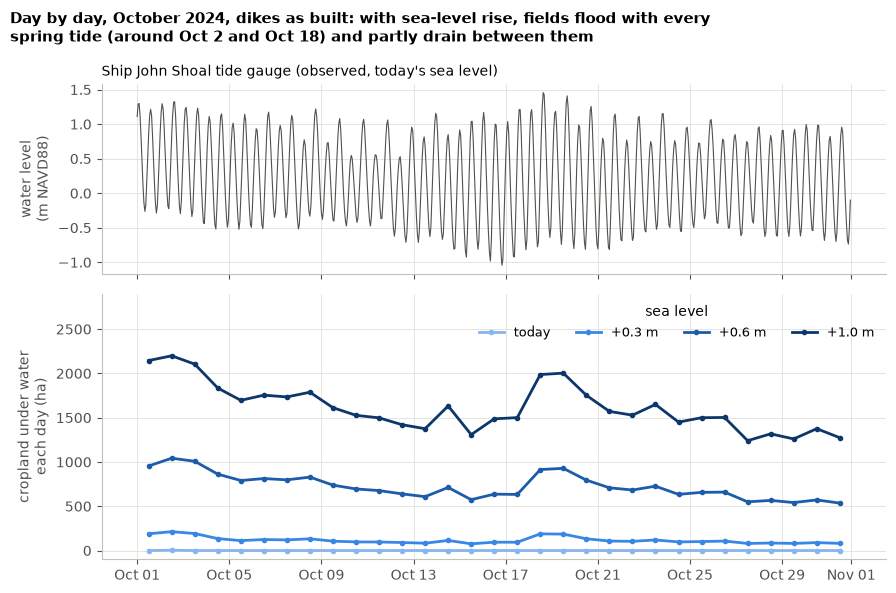

In [5]:
fig, (a1, a2) = plt.subplots(2, 1, figsize=(9, 6), sharex=True, height_ratios=[1, 1.4])
t = tide_sjs["2024-10-01":"2024-10-31 23:00"]
a1.plot(t.index, t, color="#52514e", lw=0.8)
a1.set_ylabel("water level\n(m NAVD88)")
a1.set_title("Ship John Shoal tide gauge (observed, today's sea level)", loc="left", fontsize=10,
             fontweight="normal")
for lv in LEVELS:
    s = daily_cropland_ha(f"tide2024oct_intact_slr{lv:03d}", "tide2024oct_intact_slr000")
    s = s["2024-10-01":"2024-10-31"]
    a2.plot(s.index + pd.Timedelta(hours=12), s, color=SLR_COL[lv], lw=2, marker="o", ms=3,
            label=LEVEL_NAME[lv])
a2.set_ylabel("cropland under water\neach day (ha)")
a2.legend(title="sea level", frameon=False, fontsize=9, ncol=4, loc="upper right")
a2.set_ylim(-100, 2900)
a2.xaxis.set_major_formatter(DateFormatter("%b %d"))
fig.suptitle("Day by day, October 2024, dikes as built: with sea-level rise, fields flood with every\n"
             "spring tide (around Oct 2 and Oct 18) and partly drain between them", x=0.01,
             ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

This chart counts **cropland** pixels in the USDA CDL, not whole farm fields, so its totals are
smaller than in the field map above. CDL calls much of the wettest farmland grass or wetland.
The model keeps each day's highest water, so a field wet at high tide and dry at low tide counts
as flooded that day.

## 3. Hurricane Sandy (October 2012)

Sandy's storm tide in the bay (about 1.9 m NAVD88 at Ship John Shoal) was large but not unusual
here. Similar peaks came in December 2012, January 2016 and October 2021. We ran Sandy's tide with
sea-level rise, and once with its rain as well.

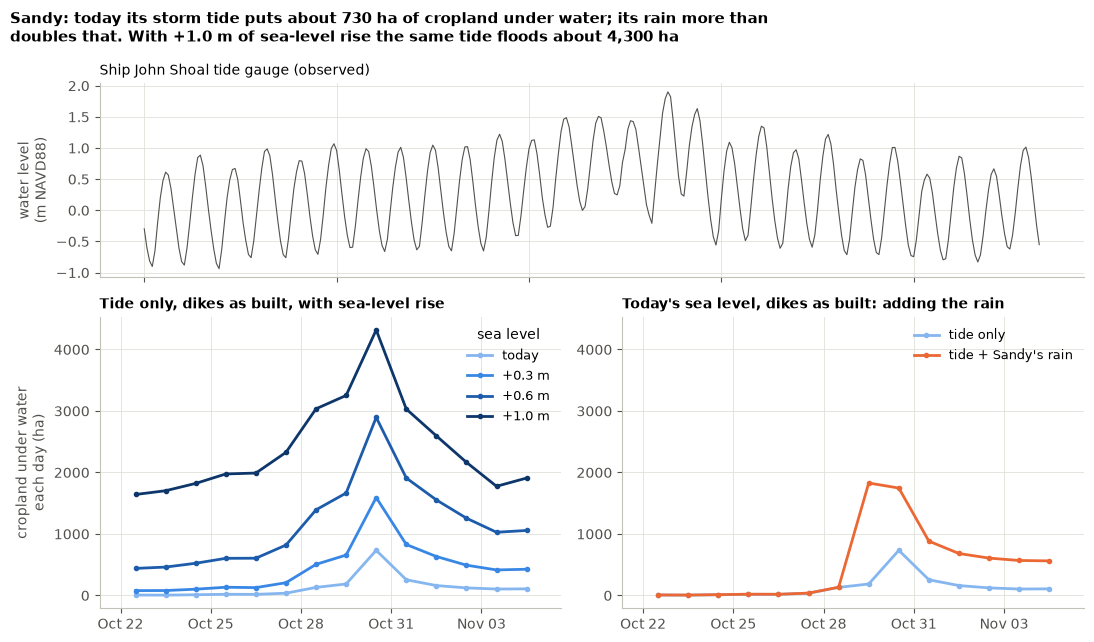

In [6]:
fig, ax = plt.subplot_mosaic([["tide", "tide"], ["slr", "rain"]], figsize=(11, 6.5),
                              height_ratios=[1, 1.5], sharex=True)
win = slice("2012-10-22", "2012-11-04 23:00")
t = tide_sjs[win]
ax["tide"].plot(t.index, t, color="#52514e", lw=0.8)
ax["tide"].set_ylabel("water level\n(m NAVD88)")
ax["tide"].set_title("Ship John Shoal tide gauge (observed)", loc="left", fontsize=10, fontweight="normal")
base = "sandy2012_intact_slr000"
for lv in LEVELS:
    s = daily_cropland_ha(f"sandy2012_intact_slr{lv:03d}", base)[win]
    ax["slr"].plot(s.index + pd.Timedelta(hours=12), s, color=SLR_COL[lv], lw=2, marker="o", ms=3,
                   label=LEVEL_NAME[lv])
ax["slr"].set_title("Tide only, dikes as built, with sea-level rise", loc="left", fontsize=10)
ax["slr"].legend(title="sea level", frameon=False, fontsize=9)
for run, lab, col in [(base, "tide only", "#86b6ef"), (base + "_rain", "tide + Sandy's rain", "#eb6834")]:
    s = daily_cropland_ha(run, base)[win]
    ax["rain"].plot(s.index + pd.Timedelta(hours=12), s, color=col, lw=2, marker="o", ms=3, label=lab)
ax["rain"].set_title("Today's sea level, dikes as built: adding the rain", loc="left", fontsize=10)
ax["rain"].legend(frameon=False, fontsize=9)
ax["rain"].sharey(ax["slr"])
ax["slr"].set_ylabel("cropland under water\neach day (ha)")
for k in ("slr", "rain"):
    ax[k].set_xticks(pd.date_range("2012-10-22", "2012-11-04", freq="3D"))
    ax[k].xaxis.set_major_formatter(DateFormatter("%b %d"))
fig.suptitle("Sandy: today its storm tide puts about 730 ha of cropland under water; its rain more than\n"
             "doubles that. With +1.0 m of sea-level rise the same tide floods about 4,300 ha",
             x=0.01, ha="left", fontweight="bold", fontsize=11)
fig.tight_layout()
plt.show()

- **On storm days today, rain does more to fields than the storm tide.**
- With rain included the water drains slowly: about 560 ha of cropland is still wet five days
  after the storm, against about 110 ha with the tide alone.
- The sea-level-rise runs are tide only (no rain), so they understate storm-day flooding.

## 4. What a data delivery looks like now

A per-field table for one scenario (October 2024 tides, dikes as built, +0.6 m). Below are a few of
the 1,273 fields that flood, sorted by flooded area. The full table also has the land-use code,
the "behind a levee" flag, and a daily file (field × day).

In [7]:
s = pd.read_csv(config.DATA / "analysis" / "sample_tide2024oct_intact_slr060" / "fields.csv")
cols = {"field_id": "field", "county": "county", "ha": "field ha", "cdl2024_crops": "crops (CDL 2024)",
        "flooded_pct": "% flooded", "first_flood_date": "first flooded", "flood_days": "days flooded",
        "longest_run_days": "longest run (days)", "depth_m": "max depth (m)"}
pd.options.display.float_format = None
(s[s.flooded & (s.cdl2024_cropland_pct >= 50)].sort_values("flooded_ha", ascending=False)
 .head(6)[list(cols)].rename(columns=cols).set_index("field")
 .style.format({"field ha": "{:.1f}", "% flooded": "{:.0f}", "max depth (m)": "{:.2f}"}))

,county,field ha,crops (CDL 2024),% flooded,first flooded,days flooded,longest run (days),max depth (m)
field,,,,,,,,
4943,Salem,316.1,Dbl Crop WinWht/Soybeans 43%; Corn 19%; Soybeans 19%,51,2024-10-01,31,31,0.70
4901,Salem,143.1,Soybeans 47%; Dbl Crop WinWht/Soybeans 32%; Corn 8%,33,2024-10-01,31,31,0.63
4669,Salem,130.5,Dbl Crop WinWht/Soybeans 25%; Soybeans 24%; Corn 15%,32,2024-10-01,25,12,0.47
6687,Cumberland,47.9,Sweet Corn 15%; Potatoes 14%; Tomatoes 12%; Soybeans 10%; Cabbage 6%,74,2024-10-01,31,31,0.53
6641,Cumberland,117.3,Potatoes 48%; Soybeans 17%; Corn 6%; Dbl Crop Barley/Corn 6%,30,2024-10-01,31,31,0.54
3319,Cumberland,128.4,Soybeans 16%; Dbl Crop WinWht/Soybeans 11%; Cucumbers 6%,24,2024-10-01,14,8,0.36


## Limits to keep in mind

- **Salt.** The model moves water, not salt. The tide here is brackish, and salt can harm a field
  for later seasons, which no single-year crop loss table covers.
- **Season.** October comes after most harvests. The same tides in spring or summer would meet
  standing crops. Other months need new runs, which are cheap (about one minute of computing per
  simulated day).
- **Tide gates.** No inventory of gate locations or sizes exists for these banks, so the model's
  gates are assumptions. This matters for how fast water leaves diked fields after a storm or
  heavy rain. It matters little for the tide-only comparisons.
- **Ground height.** Lidar can read dense marsh 0.2–0.5 m too high, and the dike crests
  predate some post-Sandy repairs.

## Questions for the ag-econ group

1. **Unit.** Is the field the right unit, or do you need farms or parcels? Do you have a way to
   link fields to farms or owners (e.g. tax parcels, farmland assessment)?
2. **Variables.** Which matter most for crop losses: maximum depth, days under water, the
   longest continuous stretch, the date (crop stage), or salt vs fresh water? Is there a
   damage function you plan to use (e.g. USACE/Hazus crop tables, which use flood date and
   duration)?
3. **Season.** Which months matter most for these crops (planting, growing, harvest)? We can
   run the same tides and storms in those months.
4. **Scenarios.** Which sea-level steps (or target years) and dike conditions are most useful?
   For example, one bank failing at a time, to set against repair costs.
5. **Format.** Is a CSV plus a GIS file (GeoPackage or shapefile) per scenario fine? Would
   you prefer one long table (field × scenario × day)?
6. **Crops.** Is the CDL crop on each field good enough, or do you have better crop, yield or
   price data to join?